## Red Neuronal con Keras - MNIST

#### Dataset propuesto : **MNIST (digitos manuscritos**)

El dataset MNIST es considerado el "Hola Mundo" de Deep Leraning. Consta de 70 000 imagenes en escala de grises de 28x28 pixeles de digitos manuscritos (del 0 al 9)

- **Entrenamiento**: 60 000
- **Prueba**: 10 000
- **Clases**: 10 (o al 9)

#### 1. Importar librerias

In [13]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

#### 2. Carga y Procesamiento de Datos

Keras incluye el conjutno de datos MNIST de forma predeterminada:

- **Cargar datos:** Division automatica en conjunto de entrenamiento y pruebas
- **Normalizacion / Escalado:** Escalamos los valores de pixeles del [0, 255] al rango [0.0, 1.0] dividiendo entre 255

In [14]:
# cargar el dataset MNIST
mnist = keras.datasets.mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [15]:
X_train

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [16]:
# cargar el dataset MNIST
mnist = keras.datasets.mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# normalizar las imagenes de 0 - 255 -> 0.0 - 0.1
X_train = X_train / 255.0
X_test = X_test / 255.0

print(f'Dimensiones de entrenamiento: {X_train.shape}')
print(f'Dimensiones de prueba: {X_test.shape}')

Dimensiones de entrenamiento: (60000, 28, 28)
Dimensiones de prueba: (10000, 28, 28)


### 3. Visualizacion de Ejemplos de Entrenamiento

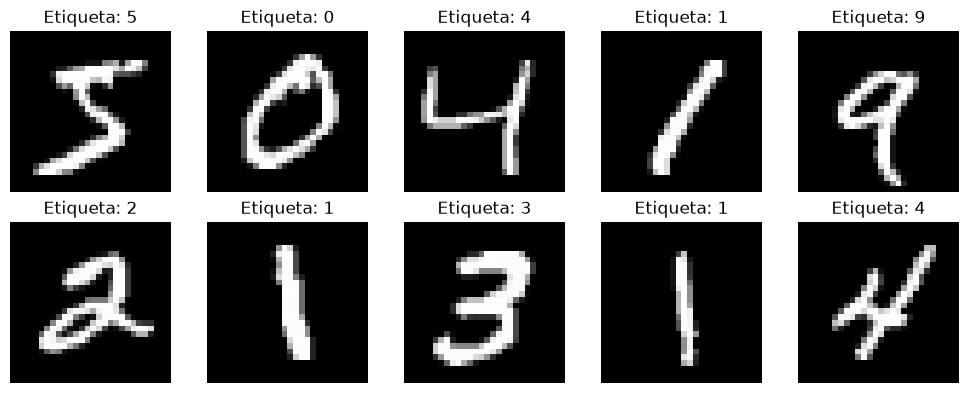

In [28]:
plt.figure(figsize=(10,4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f'Etiqueta: {y_train[i]}')
    plt.axis('off')
plt.tight_layout()
plt.show()

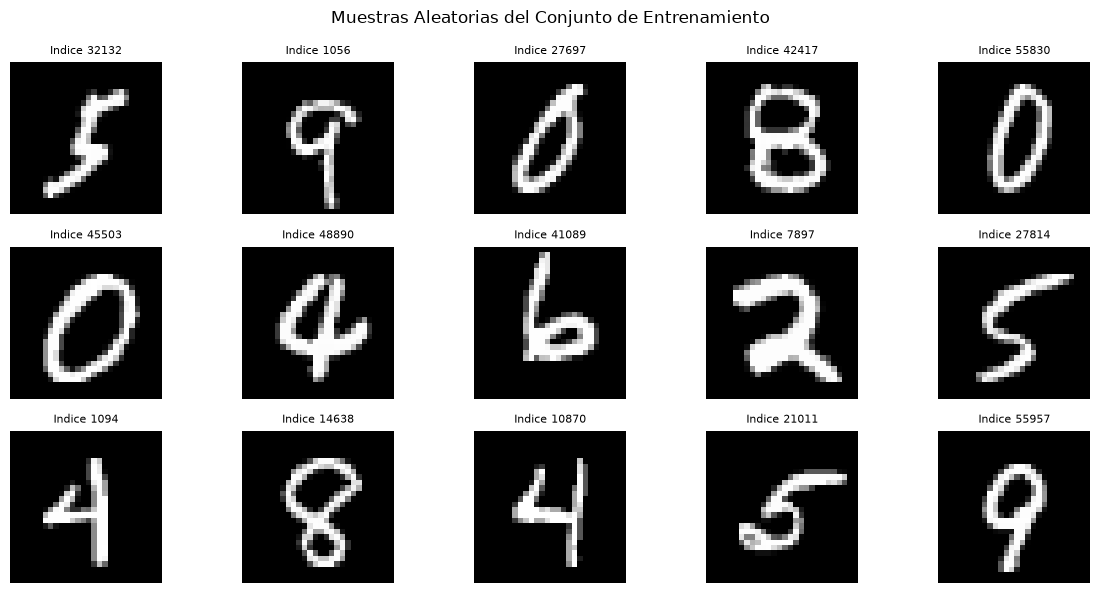

In [34]:
random_indices = np.random.choice(len(X_train), 15, replace=False)
plt.figure(figsize=(12,6))
for i, idx in enumerate(random_indices):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_train[idx], cmap='gray')
    plt.title(f'Indice {idx}', fontsize=8)
    plt.axis('off')
plt.suptitle("Muestras Aleatorias del Conjunto de Entrenamiento")
plt.tight_layout()
plt.show()

### 4. Definicion de la Arquitectura de la Red Neuronal

Diseño de un modelo secuencial (Sequential) compuesto por:

- **Capa Flatten:** Aplana la matriz de imagen de 28x28 a un vector unidimencional de 784 pixeles
- **Capa Dense Oculta:** 128 neuronas con funcion de activacion RELU
- **Capa Dropout:** Desconecta aleatoriamente el 20% de los nodos para prevenir el sobreajuste (overfitting)
- **Capa Dense Salida:** 10 neuronas con activacion Softmax. Representando la distribucion de probabilidad para cada clase (digitos 0 al 9)

In [35]:
model = keras.Sequential([
    layers.Flatten(input_shape=(28, 28), name='Capa_aplanado'),
    layers.Dense(128, activation='relu', name='Capa_oculta_1'),
    layers.Dropout(0.2, name='dropout'),
    layers.Dense(10, activation='softmax', name='capa_salida')
])

model.summary()

c:\Users\Instructor\Desktop\ingswsenati\entorno\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Capa_aplanado (Flatten)         │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Capa_oculta_1 (Dense)           │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_salida (Dense)             │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### 5. Compilacion del modelo

In [36]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### 6. Entrenamiento de la Red Neuronal

In [38]:
help(model.fit)

Help on method fit in module keras.src.backend.tensorflow.trainer:

fit(
    x=None,
    y=None,
    batch_size=None,
    epochs=1,
    verbose='auto',
    callbacks=None,
    validation_split=0.0,
    validation_data=None,
    shuffle=True,
    class_weight=None,
    sample_weight=None,
    initial_epoch=0,
    steps_per_epoch=None,
    validation_steps=None,
    validation_batch_size=None,
    validation_freq=1
) method of keras.src.models.sequential.Sequential instance
    Trains the model for a fixed number of epochs (dataset iterations).

    Args:
        x: Input data. It can be:
            - A NumPy array (or array-like), or a list of arrays
            (in case the model has multiple inputs).
            - A backend-native tensor, or a list of tensors
            (in case the model has multiple inputs).
            - A dict mapping input names to the corresponding array/tensors,
            if the model has named inputs.
            - A `keras.utils.PyDataset` returning `(inp

In [39]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8953 - loss: 0.3649 - val_accuracy: 0.9557 - val_loss: 0.1603
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9487 - loss: 0.1766 - val_accuracy: 0.9690 - val_loss: 0.1126
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9622 - loss: 0.1306 - val_accuracy: 0.9747 - val_loss: 0.0851
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9682 - loss: 0.1055 - val_accuracy: 0.9783 - val_loss: 0.0752
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9733 - loss: 0.0893 - val_accuracy: 0.9793 - val_loss: 0.0716


### 7. Evaluacion del modelo en datos de prueba

In [40]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=2)

print(f'\nPresicion en datos de prueba (test accuracy): {test_acc * 100:.2f}%')
print(f'Perdida en datos de prueba (test loss): {test_loss:.2f}')

313/313 - 0s - 633us/step - accuracy: 0.9764 - loss: 0.0778

Presicion en datos de prueba (test accuracy): 97.64%
Perdida en datos de prueba (test loss): 0.08


### 8. Realizacion de predicciones individuales

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


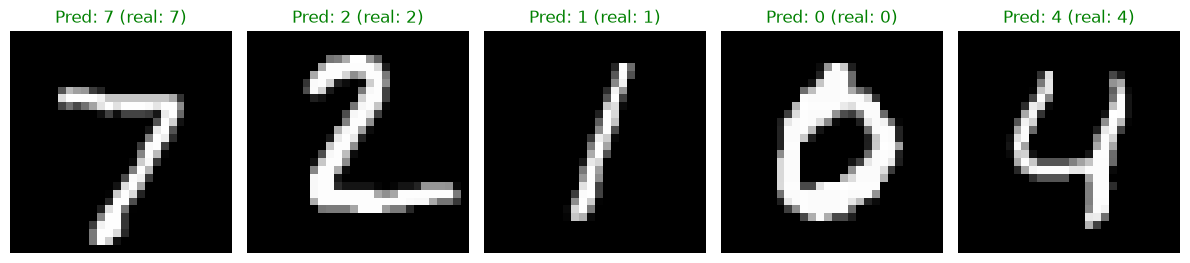

In [43]:
predictions = model.predict(X_test[:5])

plt.figure(figsize=(12, 3))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(X_test[i], cmap='gray')
    pred_label = np.argmax(predictions[i])
    true_label = y_test[i]
    color = 'green' if pred_label == true_label else 'red'
    plt.title(f'Pred: {pred_label} (real: {true_label})', color=color)
    plt.axis('off')
plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


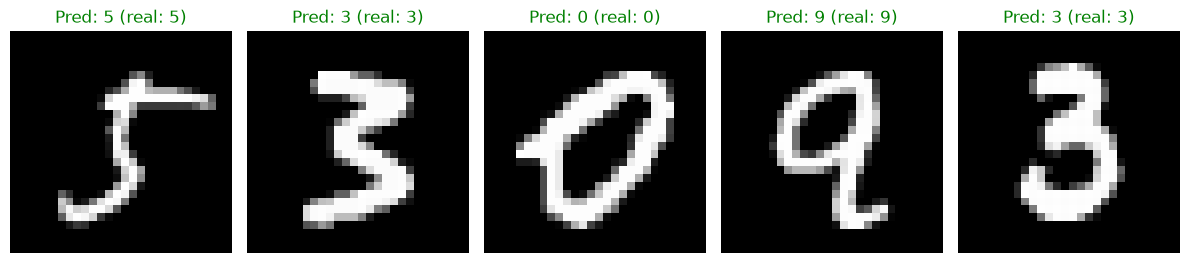

In [49]:
indices_aleatorios = np.random.choice(len(X_test), size=5, replace=False)

imagenes_muestra = X_test[indices_aleatorios]
etiquetas_reales = y_test[indices_aleatorios]

predictions = model.predict(imagenes_muestra)

plt.figure(figsize=(12, 3))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(imagenes_muestra[i], cmap='gray')
    pred_label = np.argmax(predictions[i])
    true_label = etiquetas_reales[i]
    color = 'green' if pred_label == true_label else 'red'
    plt.title(f'Pred: {pred_label} (real: {true_label})', color=color)
    plt.axis('off')
plt.tight_layout()
plt.show()